In this lab, we will build a model to perform segmentation of RNA molecules, seen as surfaces.

![](https://www.lix.polytechnique.fr/Labo/Robin.Magnet/INF631/rna_image.png)

For this, we will first build a network able to process these surfaces, and then train it on the dataset.
We will additionnally try some small variations and check their effects.

# Environment and data

Let's download the dataset and additional necessary packages.

You will need a GPU for this Lab. We recommend to use Google Colab.

In [ ]:
!pip install potpourri3d
!pip install git+https://github.com/skoch9/meshplot.git
!pip install pythreejs

#!wget https://www.lix.polytechnique.fr/Labo/Robin.Magnet/INF631/RNADataset.zip
#!wget https://www.lix.polytechnique.fr/Labo/Robin.Magnet/INF631/material_TD3.zip

In [12]:
!unzip -qq RNADataset.zip
!unzip -qq material_TD3.zip

Code for colab

In [13]:
from google.colab import output
output.enable_custom_widget_manager()

import os

import torch
import torch.nn as nn


#import diffusion_utils

# Part I - Implementing Diffusion DiffusionNet

## Goal

In this assignment we will focus on building [DiffusionNet](https://arxiv.org/pdf/2012.00888.pdf), which was presented during the lecture.
This network uses differential geometry tools to compute per-vertex features which can later be used for several tasks such as classification, segmentation or matching.

Recall that the DiffusionNet architechture can be visualized as follows :

![](https://www.lix.polytechnique.fr/Labo/Robin.Magnet/INF631/TD3/DiffusionNet.PNG)


Therefore, following this image, we will build the following objects using PyTorch:
1. **Precomputed operators**. Most of them have been introduced in TD1, the gradient matrix is provided in the `diffusion_utils.py` file provided with this TD (do not modify it!).
2. **Spatial Diffusion**. Using again TD1 (part on spectral diffusion).
3. **Spatial Gradient features**. Using gradient matrices
4. **Per-vertex MLP**. Basic PyTorch
5. **DiffusionNet block** and **DiffusionNet** which consists in assembling the previous 4 parts.

## Reminders on PyTorch
[Pytorch](https://pytorch.org/docs/stable/index.html) is a standard library to build and train neural networks. Two essential components are auto-differentiation and GPU support with parallelization of operations.

A [`torch.Tensor`](https://pytorch.org/docs/stable/tensors.html) object is very similar to a `numpy.array`, and most existing operations in numpy have identical equivalent in PyTorch. However behaviors can be slightly different so always check the documentation ! Using built-in PyTorch functions instead of numpy enables automatic gradient computation.

Note that PyTorch operations are built to be significantly accelerated on GPU by using parallel computing. This implies that the first dimension of a `torch.Tensor` is most often interpreted as the batch dimension and operations are applied *in parallel* to each element of the batch **independently**.
For instance, given a tensor `A` of size `[M,N]` and a tensor `X` of size `[B,N,P]`, the output of `A @ X` will be of size `[B,M,P]`, where the matrix multiplication by `A` is applied to each of the `X[i]` in parallel.

In DiffusionNet, some blocks (*eg* the diffusion block) can be applied to multiple surfaces in parallel so batches are made of surfaces. On the contrary the MLP or gradient features blocks are applied to each vertex independantly so the batches are made of vertices. This will require some particular care when coding.

## 1 - Implementing Diffusion Net

In this section, we seek to implement a version of DiffusionNet which only handles oriented triangle meshes.

It will be impossible for you to test that the output of the functions are the right ones before the complete pipeline is built. However, since shapes are provided in the description of each function, you can ensure each module outputs a tensor of the right shape.

## 1.1 - Some utils

We here code 2 utility functions used in the diffusion block, which allow to project  (resp. unproject) functions to (resp. from) the spectral basis **taking the batch dimension** into account.

For simplicity, we use a batch size = $1$ in this TD as it's tricky to combine functions defined on a mesh with $n_1$ vertices with functions defined on another mesh with $n_2$ vertices.


**Projection**: Recall from TD1, that given functions on a mesh stored in a matrix $\mathbf{f}\in\mathbb{R}^{n\times p}$, the projection into the spectral basis of size $K$ can be done via the matrix multiplication $\Phi^\top A \mathbf{f}$, where $\Phi\in\mathbb{R}^{n\times K}$ are the eigenvectors of the laplacian of the shape and A the area matrix of the shape.

**Reverse projection**: Recall from TD1, that given spectral coefficients of functions on a mesh stored in a matrix $\alpha\in\mathbb{R}^{K\times p}$, the corresponding functions on the mesh are defined as $\Phi \alpha \in\mathbb{R}^{n\times p}$.

### Question 1
**Compute the projection and reverse projection functions, which take batch of functions**

**Tips**:
1. If `A` is to torch Tensor of shape `(B,N,M)`, then `A.mT` does batch-wise matrix transpose and has shape `(B,M,N)`
2. Given a diagonal matrix $A$ and a function $f\in\mathbb{R}^n$, then $Af = \left(A_{ii}f_i\right)$, where $A_{ii}$ are the diagonal values of $A$ (vertex areas in our case). We therefore directly use the diagonal values as input.
3. For matrix multiplication, multiple operations are possibly, namely torch.mm, torch.einsum or the traditional @ operator. Choose what you understand the most easily.


In [14]:
def project_to_basis(x, evecs, vertex_areas):
    """
    Project an input sinal x to the spectral basis.


    Parameters
    -------------------
    x            : (B, n, p) Tensor of input
    evecs        : (B, n, K) Tensor of eigenvectors
    vertex_areas : (B, n,) vertex areax

    Output
    -------------------
    projected_values : (B, K, p) Tensor of coefficients in the basis
    """
    return evecs.mT @ (vertex_areas.unsqueeze(-1) * x)




def unproject_from_basis(coeffs, evecs):
    """
    Transform input coefficients in basis into a signal on the complete shape.

    Parameters
    -------------------
    coefs : (B, K, p) Tensor of coefficients in the spectral basis
    evecs : (B, n, K) Tensor of eigenvectors

    Output
    -------------------
    decoded_values : (B, n, p) values on each vertex
    """
    return evecs @ coeffs

## 1.2 - Spectral Diffusion module

The DiffusionModule in Diffusion takes as input a mesh $M$ and set of functions $\left(f_1,\dots, f_p\right)$  on the mesh - that is $f_j:M\to\mathbb{R}$ - and outputs $\left(g_1,\dots, g_p\right)$ with $g_j:M\to\mathbb{R}$ and where $g_j$ the the **diffused version** of $f_j$ after time $t_j$.

Note that each feature function $f_j$ is diffused for time $t_j$ where the time parameter **depends on the index of the function**.
DiffusionNet proposes to **learn each time parameter** $t_1,\dots, t_p$. There is therefore $p$ learnable parameters in this module.


In order to compute Diffusion efficiently, we will use the spectral diffusion approximation introduced in TD1.

Recall from that TD1 that the Laplacian eigenvectors of a mesh made of $N$ vertices can stored in a matrix $\Phi\in\mathbb{R}^{N\times K}$.
Given an initial function $f_0$, its (spectral) diffused version $f_t$ after time $t$ can be written $f_t = \Phi \alpha_t$ with
$$
(\alpha_t)_j = \exp(-t\lambda_j)\beta_j
$$

where $\beta=\Phi^\top A f_0 \ \in\mathbb{R}^K$ is the projection of $f_0$ in the basis, and $A$ the diagonal area matrix.

### Question 2
**Fill the SpectralDiffusion module which diffuses features with learnable time parameters.**

**Clue:**
1. Use [`nn.Parameter`](https://pytorch.org/docs/stable/generated/torch.nn.parameter.Parameter.html) to create learnable parameters in a module
2. Use [`nn.init.constant_`](https://pytorch.org/docs/stable/nn.init.html#torch.nn.init.constant_) to initialize time parameters to 0
3. Be careful about the dimension of inputs, outputs, intermediate tensors, ...

In [15]:
import numpy as np

class SpectralDiffusion(nn.Module):

    def __init__(self, n_channels):
        """
        Initializes the module with time parameters to 0.

        Parameters
        ------------------
        n_channels : int - number of input feature functions
        """
        # This runs the __init__ function of nn.Module
        super().__init__()

        self.n_channels = n_channels

        ## TODO DEFINE AND INITIALIZE THE Diffusion times as learnable parameters.
        self.diffusion_times = nn.Parameter(torch.empty(n_channels))
        nn.init.constant_(self.diffusion_times, 0.0)


    def forward(self, x, evals, evecs, vertex_areas):
        """
        Given input features x and information on the current meshes
        return diffused versions of the features.

        Parameters
        ------------------------
        x     : (B, n, p) batch of input features. p = self.n_channels
        evals : (B, K,) batch of eigenvalues
        evecs : (B, n, K) batch of eigenvectors
        vertex_areas : (B, n,) batch of vertex areax


        Output
        ------------------------
        x_diffuse : diffused version of each input feature
        """
        # Remove negative diffusion times
        with torch.no_grad():
            self.diffusion_times.data = torch.clamp(self.diffusion_times, min=1e-8)

        ## TODO DIFFUSE x
        c = project_to_basis(x, evecs, vertex_areas)
        decay = torch.exp(-evals.unsqueeze(-1) * self.diffusion_times)
        x_diffused = unproject_from_basis(decay * c, evecs)


        return x_diffused

## 1.3 Gradient Features module

The gradient feature module allows to compute features from the gradient of the diffused feature. This module treats **each vertex independantly**. The batch size is here the number of vertices and not the shape as a whole.

This modules takes as input **the gradient of each feature** at a vertex, and outputs **a real number for each feature** for this vertex.


The gradient of the features is a **vector field**, so a pair of numbers at each vertex. In practice, the value at a vertex $v$ is stored as a complex number $z\in\mathbb{C}^n$. Because there are $p$ different features for each vertex, we concatenate the $p$ gradients (one for each feature) and obtain a per-vertex vector field $w_v\in\mathbb{C}^{p}$ as **input**.

The gradient feature module therefore takes a vertex embedding $w_v$ as input and outputs a *real-valued* embedding $g_v\in\mathbb{R}^{p}$ where

$$
g_v = \tanh\left(\langle w_v, B w_v\rangle_{\mathbb{C}}\right)
$$
with $\tanh$ and $\langle\rangle_{\mathbb{C}}$ applied **element-wise**.


Where $B$ is a **complex and learnable** matrix, and $\langle\rangle_{\mathbb{C}}$ can be seen as the $\mathbb{R}^2$ inner product when identifying $\mathbb{C}$ with $\mathbb{R}^2$. This means for $a,b,c,d\in\mathbb{R}$ that:
$$
\langle a+ib, c+id\rangle_{\mathbb{C}} = ac + bd
$$


In summary, the gradient feature module:
 - Takes $w_v\in\mathbb{C}^{p}$ as input
 - Computes $g_v$ using the formula above
 - Has $B\in\mathbb{C}^p$ as a unique parameter

### Question 3
**Implement the Gradient Feature Module**

**Tips**:

1. In practice, use $w_v\in\mathbb{R}^{p\times 2}$ and $B=B_{re}+iB_{im}$ where both matrix are real values $p\times p$ matrices. Compute separately the real and imaginary part of $Bw_v$, then apply the inner product and hyperbolic tangent element-wise.
2. A learnable matrix multipication can be represented as a [`nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) layer

In [16]:
class SpatialGradient(nn.Module):
    """
    Module which computes g_v from vertex embeddings.
    """
    def __init__(self, n_channels):
        """
        Initializes the module.

        Parameters
        ------------------
        n_channels : int - number of input feature functions
        """

        super().__init__()

        self.n_channels = n_channels

        # Real and Imaginary part of B
        self.B_re = nn.Linear(self.n_channels, self.n_channels, bias=False)
        self.B_im = nn.Linear(self.n_channels, self.n_channels, bias=False)

    def forward(self, vects):
        """
        Parameters
        ----------------------
        Vects : (N, P, 2) per-vertex vector field (w_v)

        Output
        ---------------------
        features : (N, P) per-vertex scalar field
        """
        vects_re = vects[...,0]  # (N,P) real part of w_v
        vects_im = vects[...,1]  # (N,P) imaginary part of w_v

        ## TODO Perform forward pass
        Bv_re = self.B_re(vects_re) - self.B_im(vects_im)
        Bv_im = self.B_re(vects_im) + self.B_im(vects_re)

        inn_prod = vects_re * Bv_re + vects_im * Bv_im

        return torch.tanh(inn_prod)


## 1.4 MLP module

The MLP module is a simple multi-layer perceptron which acts on **each vertex independantly**.

This can be customizable using custom hidden layer sizes and droupout.

### Question 4
**Code the MiniMLP module (with dropout and activation)**

**Tip**:
1. Activation is not applied to the last layer
2. Given a list `layer_list` of `torch.nn` modules, one can generate a large layer using `nn.Sequential(*layer_list)`. See the [documentation](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html) for more info
3. Batch is made of per-vertex embedding, not per surface.

In [17]:
def block(input_size, output_size, activation, dropout_p = False, act = True):
  layers = [nn.Linear(input_size, output_size)]

  if act:
      if activation is not None:
          layers.append(activation())
      if dropout_p:
          layers.append(nn.Dropout(p=0.2))

  return layers

class MiniMLP(nn.Sequential):
    '''
    A simple MLP with activation and potential dropout
    '''
    def __init__(self, layer_sizes, dropout=False, activation=nn.ReLU):
        """
        Activation and dropout is applied after all layer BUT the last one

        Parameters
        ---------------------------
        layer_size : list of ints - list of sizes of the MLP
        dropout    : book - whether to add droupout or not
        activation : nn.module : activation function
        """
        super().__init__()
        self.dropout = dropout
        self.act = activation

        layers = []
        for i in range(len(layer_sizes) - 1):
            is_last = i == len(layer_sizes) - 2
            layers.extend(
                block(
                    layer_sizes[i],
                    layer_sizes[i + 1],
                    activation=self.act,
                    dropout_p=self.dropout,
                    act= not is_last,
                )
            )

        ## TODO FILL THE LAYER LIST
        self.layer_list = nn.Sequential(*layers)

    def forward(self, x):
        """
        Parameters
        --------------------
        x : (n, p) - input features, batch size is the number of vertices !

        Output
        -------------------
        y : (n,p') - output features
        """
        # NOTHING TO DO HERE
        return self.layer_list(x)

## 1.5 DiffusionNet Block

![](https://www.lix.polytechnique.fr/Labo/Robin.Magnet/INF631/TD3/DiffusionNet.PNG)

Each diffusion block contains 3 main modules which were implemented in the preceeding three questions. Namely, (1) Learned spectral diffusion, (2) Gradient Feature module and (3) Point-wise features from the MLP module applied sequentially.

Note the following points:
1. Input and output are per-vertex scalars
2. The width (or number of features) is the same as input and output
3. The Diffusion module uses the input features as input.
4. The Spatial Gradient module uses the **gradient** of the output of the Diffusion module as input
5. The MiniMLP uses the **concatenation** of the input features, the output of the Diffusion module and the output of the Spatial Gradient module as input. Its input size is 3 times the number of features.
6. The input features are **added** to the output using a **residual connection**.


### Question 5

**Assemble the Diffusion + Gradient + MLP modules to construct diffusion block using the image and explanation above**

**Tip**
 - We pre-filled the code to compute the gradient of the features
 - We only provide the size of the **hidden** layers of the MLP. You must add the input and output dimension.

In [18]:
class DiffusionNetBlock(nn.Module):
    """
    Complete Diffusion block
    """

    def __init__(self, n_channels, mlp_hidden_dims, dropout=True):
        """
        Initializes the module.

        Parameters
        ------------------
        n_channels      : int - number of feature functions (serves as both input and output)
        mlp_hidden_dims : list of int - sizes of HIDDEN layers of the miniMLP.
                          You should add the input and output dimension to it.
        """
        super(DiffusionNetBlock, self).__init__()

        # Specified dimensions
        self.n_channels = n_channels

        self.dropout = dropout

        # Diffusion block
        # TODO DEFINE THE 3 SUBPARTS
        self.diffusion = SpectralDiffusion(n_channels)
        self.spatial_gradient = SpatialGradient(n_channels)
        self.MLP = MiniMLP([3*n_channels] + mlp_hidden_dims + [n_channels], dropout)


    def forward(self, x_in, vertex_areas, evals, evecs, gradX, gradY):
        """
        Parameters
        -------------------
        x_in         : (B,n,p) - Tensor of input signal.
        vertex_areas : (B,n) - Tensor of vertex areas
        evals        : (B, K,) batch of eigenvalues
        evecs        : (B, n, K) batch of eigenvectors
        gradX        : Half of gradient matrix, sparse real tensor with dimension [B,N,N]
        gradY        : Half of gradient matrix, sparse real tensor with dimension [B,N,N]

        Output
        -------------------
        x_out : (B,n,p) - Tensor of output signal.
        """

        # Manage dimensions
        B = x_in.shape[0] # batch dimension

        # Diffusion block
        x_diffuse = self.diffusion(x_in, evals, evecs, vertex_areas) # DIFFUSED X_in  # (B, N, p)


        # Compute the batch of gradients
        x_grads = [] # Manually loop over the batch
        for b in range(B):
            # gradient after diffusion
            x_gradX = torch.mm(gradX[b,...], x_diffuse[b,...])
            x_gradY = torch.mm(gradY[b,...], x_diffuse[b,...])

            x_grads.append(torch.stack((x_gradX, x_gradY), dim=-1))

        x_grad = torch.stack(x_grads, dim=0)  # (B, N, P, 2)

        # TODO EVALUATE GRADIENT FEATURES

        grad_feat = self.spatial_gradient(x_grad)

        # TODO APPLY THE MLP TO THE CONCATENATED FEATURES

        out = self.MLP(torch.cat((x_in, x_diffuse, grad_feat), dim = 2))

        # TODO APPLY THE RESIDUAL CONNECTION
        out = out + x_in

        return out

## 1.6 - DiffusionNet

Let's check again the architecture:
![](https://www.lix.polytechnique.fr/Labo/Robin.Magnet/INF631/TD3/DiffusionNet.PNG)

DiffusionNet takes as input per-vertex features of size $p_{in}$. Is first uses a linear layer to transform theses features into $p$-dimensional features, where $p$ is the width of DiffusionNet. There are then multiple blocks of DiffusionNetBlock to produce new features. Similarly to input features, a last linear layer transforms the $p$ dimensional features into vertex features of size $p_{out}$

### Question 6

**Build the DiffusionNet. It consists of an MLP in the first layer to reac with `N_block` of `DiffusionNetBlock` which was implemented in the previous cell.**

In [19]:
class DiffusionNet(nn.Module):

    def __init__(self, p_in, p_out, n_channels=128, N_block=4, last_activation=None, mlp_hidden_dims=None, dropout=True, block_cls=DiffusionNetBlock):
        """
        Construct a DiffusionNet.
        Parameters
        --------------------
        p_in            : int - input dimension of the network
        p_out           : int - output dimension  of the network
        n_channels      : int - dimension of internal DiffusionNet blocks (default: 128)
        N_block         : int - number of DiffusionNet blocks (default: 4)
        last_activation : int - a function to apply to the final outputs of the network, such as torch.nn.functional.log_softmax
        mlp_hidden_dims : list of int - a list of hidden layer sizes for MLPs (default: [C_width, C_width])
        dropout         : bool - if True, internal MLPs use dropout (default: True)
        """

        super(DiffusionNet, self).__init__()

        ## Store parameters

        # Basic parameters
        self.p_in = p_in
        self.p_out = p_out
        self.n_channels = n_channels
        self.N_block = N_block

        # Outputs
        self.last_activation = last_activation

        # MLP options
        if mlp_hidden_dims == None:
            mlp_hidden_dims = [n_channels, n_channels]
        self.mlp_hidden_dims = mlp_hidden_dims
        self.dropout = dropout


        ## TODO SETUP THE NETWORK (LINEAR LAYERS + BLOCKS)

        self.blocks = [MiniMLP([p_in] + mlp_hidden_dims + [n_channels], dropout)] + [block_cls(n_channels, mlp_hidden_dims, dropout=self.dropout) for _ in range(N_block)] + [MiniMLP([n_channels] + mlp_hidden_dims + [p_out], dropout)] # TOFILL
        self.net = nn.ModuleList(self.blocks) # you can then access each block by self.net[i]


    def forward(self, x_in, vertex_areas, evals=None, evecs=None, gradX=None, gradY=None):
        """
        Progapate a signal through the network.
        Can handle input without batch dimension (will add a dummy dimension to set batch size to 1)

        Parameters
        --------------------
        x_in         : (n,p) or (B,n,p) - Tensor of input signal.
        vertex_areas : (n,) or (B,n) - Tensor of vertex areas
        evals        : (B, K,) or (K,) batch of eigenvalues
        evecs        : (B, n, K) or (n, K) batch of eigenvectors
        gradX        : Half of gradient matrix, sparse real tensor with dimension [N,N] or [B,N,N]
        gradY        : Half of gradient matrix, sparse real tensor with dimension [N,N] or [B,N,N]

        Output
        -----------------------
        x_out (tensor):    Output with dimension [N,C_out] or [B,N,C_out]
        """


        ## Check dimensions, and append batch dimension if not given
        if x_in.shape[-1] != self.p_in:
            raise ValueError(f"DiffusionNet was constructed with p_in={self.p_in}, "
                             f"but x_in has last dim={x_in.shape[-1]}")
        N = x_in.shape[-2]

        if len(x_in.shape) == 2:
            appended_batch_dim = True

            # add a batch dim to all inputs
            x_in = x_in.unsqueeze(0) # (B, N, P)
            vertex_areas = vertex_areas.unsqueeze(0) # (B, N)
            if evals != None: evals = evals.unsqueeze(0) # (B,K)
            if evecs != None: evecs = evecs.unsqueeze(0) # (B,N,K)
            if gradX != None: gradX = gradX.unsqueeze(0) # (B,N,N)
            if gradY != None: gradY = gradY.unsqueeze(0) # (B,N,N)

        elif len(x_in.shape) == 3:
            appended_batch_dim = False

        else: raise ValueError("x_in should be tensor with shape (n,p) or (B,n,p)")

        ##  TODO PROCESS THE INPUTS

        x_out = self.net[0](x_in)
        for mod in self.net[1:-1]:
          x_out = mod(x_out, vertex_areas, evals, evecs, gradX, gradY)

        x_out = self.net[-1](x_out)

        if self.last_activation is not None:
            x_out = self.last_activation(x_out)

        # Remove batch dim if we added it
        if appended_batch_dim:
            x_out = x_out.squeeze(0) # (N, p_out)

        return x_out

# Part II - RNA segmentation.

**Given meshes of the molecular envelopes for RNA molecules, gathered from the PDB database, we will be segementing them. That is, each vertex is assigned a ground-truth segmentation label according to ~120 functional categories. See [1] for more details. We use this data as a representative task for 3D machine learning on surfaces, predicting the functional segmentation from only the molecule surface shape using DiffusionNet.**


[1] https://hal.inria.fr/hal-02167454v2/document

## 1. Visualize the data

Here is some code to visualize the training data with segmentation of the surfaces.

In [20]:
from rna_dataset import RNAMeshDataset
from mesh_utils.mesh import TriMesh
import matplotlib.pyplot as plt
import plot_utils as plu

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [22]:
root_dir = './RNADataset/'

train_dataset = RNAMeshDataset(root_dir, train=True, num_eig=128, op_cache_dir=None)

loading 60 files: ['5JUO_D.off', '5T62_B.off', '4WCE_Y.off', '4V9K_BB.off', '5E81_16.off', '3J92_7.off', '4V7X_BB.off', '5T7V_C.off', '4TUE_RB.off', '5DGE_3.off', '4V7B_BB.off', '4U4O_3.off', '3JA1_LB.off', '3PIO_Y.off', '5EL7_16.off', '5MDY_3.off', '5H5U_B.off', '4U4O_7.off', '5TBW_AS.off', '5J30_RB.off', '4W4G_RB.off', '4V7J_AB.off', '4V8J_BB.off', '2OTJ_9.off', '4V7X_DB.off', '3J9Y_B.off', '1VQK_9.off', '1Q82_B.off', '4W2H_DB.off', '3G4S_9.off', '1NKW_9.off', '4V5J_BB.off', '3JBN_AB.off', '4V8E_CB.off', '4YZV_YB.off', '4V9P_CB.off', '5J5B_DB.off', '4U6F_7.off', '5OBM_7.off', '3JCD_B.off', '4V55_BA.off', '5IBB_16.off', '1VY7_BB.off', '5GAD_B.off', '4U4Q_3.off', '4WRA_1J.off', '5ADY_A.off', '4V70_BB.off', '4TUB_RB.off', '5AJ0_A4.off', '1KD1_B.off', '4V6N_AA.off', '4V8I_BB.off', '4W4G_YB.off', '4V8F_DB.off', '4V8P_E3.off', '4V5Y_BA.off', '4TUA_YB.off', '5DFE_RB.off', '4V5K_DB.off']


In [ ]:
# This loads all operators

data1 = train_dataset[19]
mesh1 = TriMesh(data1['vertices'].numpy(), data1["faces"].numpy())

data2 = train_dataset[37]
mesh2 = TriMesh(data2['vertices'].numpy(), data2["faces"].numpy())


## You can see what kind of information is provided
print(data1.keys())

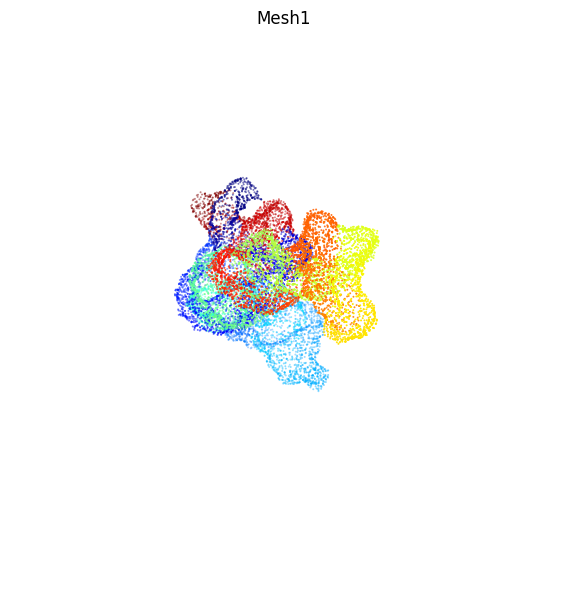

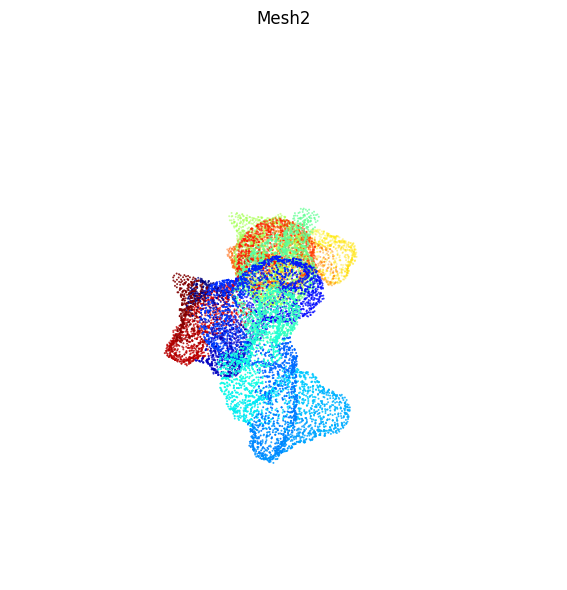

In [24]:
def plot_labels(verts, colors, title=None, s=2):
    verts = np.asarray(verts)
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(verts[:, 0], verts[:, 1], verts[:, 2], c=colors, s=s, linewidths=0)
    ax.set_box_aspect(np.ptp(verts, axis=0))
    ax.set_axis_off()
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


cmap1 = plt.get_cmap("jet")(data1["labels"].numpy() / (train_dataset.n_classes-1))[:,:3]
cmap2 = plt.get_cmap("jet")(data2["labels"].numpy() / (train_dataset.n_classes-1))[:,:3]

plot_labels(data1["vertices"], cmap1, "Mesh1")
plot_labels(data2["vertices"], cmap2, "Mesh2")

### Load training and validation dataset

All operators and eigenfunctions are precomputed and saved in a cache folder. Computing the cache can take a few minutes.

If you are using colab, you might want first to mount your drive and save the cache there (You can change the `op_cache_dir`) so that you don't have to recompute it everytime. Or either compute the cache once, download it and upload it again everytime. This might be faster than recomputing all along.

To access your google drive, use this code:


```
from google.colab import drive
drive.mount('/content/drive')
```

This makes your Drive available at `/content/drive/My Drive/`

In [ ]:
# WARNING: Do not change this cell

from rna_dataset import RNAMeshDataset
from torch.utils.data import DataLoader

root_dir = './RNADataset/'
op_cache_dir = './RNADataset/cache'
num_eig = 128

train_dataset = RNAMeshDataset(root_dir, train=True, num_eig=num_eig, op_cache_dir=op_cache_dir)
train_loader = DataLoader(train_dataset, batch_size=None, shuffle=True, num_workers=0, persistent_workers=False)

valid_dataset = RNAMeshDataset(root_dir, train=False, num_eig=num_eig, op_cache_dir=op_cache_dir)
valid_loader = DataLoader(valid_dataset, batch_size=None, num_workers=0, persistent_workers=False, )

## 2 -  Training the network

##  <font color='red'>Requirement: we need you to save the model weights and send it with the notebook to be evaluated on this question. Otherwise, this question will not reward points</font>

In order to easily run multiple experiments, we will use a class `Trainer` to run the complete training and testing code.

This way we can simply change parameters as arguments when building the class and run the training easily.

### Question 7: Fill the trainer class

This function is mostly pre-filled. Here are the parts you should implement yourself:

1. In the `__init__` function, **build DiffusionNet** using the `model_cfg` dictionary you will provide as input. An example of model config is the following:

```python
model_cfg = {'inp_feat': 'xyz',  # Type of input Features (xyz, HKS, WKS)
              'num_eig': 32,  # Number of eigenfunctions to use for Spectral Diffusion
              'p_in': 3,  # Number of input features
              'p_out': train_dataset.n_classes,  # Number of output features
              'N_block': 4,  # Number of DiffusionNetBlock
              'n_channels': 128}  # Width of the network
```

2. In the `__init__` function, **define the loss**. Note that segmentation is essentially multi-label classification. The number of classes is given by `train_dataset.n_classes`.

3. Fill in the `forward_step` `train_epoch`, `valid_epoch` methods. Note this is pretty simple and depends on your choice of loss / activation function combination.



In [26]:
# You can remove prints if you want
from tqdm.notebook import tqdm
class Trainer(object):

    def __init__(self, diffusionnet_cls, model_cfg, train_loader, valid_loader, device='cuda',
                 lr=1e-3, weight_decay=1e-4, num_epochs=200,
                 lr_decay_every = 50, lr_decay_rate = 0.5,
                 log_interval=10, save_dir=None):

        """
        diffusionnet_cls: (nn.Module) class of the DiffusionNet model
        model_cfg: (dict) keyword arguments for model
        train_loader: (torch.utils.DataLoader) DataLoader for training set
        valid_loader: (torch.utils.DataLoader) DataLoader for validation set
        device: (str) 'cuda' or 'cpu'
        lr: (float) learning rate
        weight_decay: (float) weight decay for optimiser
        num_epochs: (int) number of epochs
        lr_decay_every: (int) decay learning rate every this many epochs
        lr_decay_rate: (float) decay learning rate by this factor
        log_interval: (int) print training stats every this many iterations
        save_dir: (str) directory to save model checkpoints
        """

        # TODO build the network from the model_cfg
        self.model = diffusionnet_cls(
            p_in=model_cfg['p_in'],
            p_out=model_cfg['p_out'],
            n_channels=model_cfg.get('n_channels', 128),
            N_block=model_cfg.get('N_block', 4),
            last_activation=model_cfg.get('last_activation', None),
            mlp_hidden_dims=model_cfg.get('mlp_hidden_dims', None),
            dropout=model_cfg.get('dropout', True),
            block_cls = model_cfg.get('block_cls', DiffusionNetBlock)
        )





        self.loss = nn.CrossEntropyLoss() ## USE A MEANINGFUL LOSS



        ## THIS PART JUST STORES SOME OTHER PARAMETERS
        self.train_loader = train_loader
        self.valid_loader = valid_loader
        self.device = device
        self.lr = lr
        self.weight_decay = weight_decay
        self.num_epochs = num_epochs

        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=self.lr, weight_decay=self.weight_decay)


        self.lr_decay_every = lr_decay_every
        self.lr_decay_rate = lr_decay_rate
        self.log_interval = log_interval
        self.save_dir = save_dir

        self.train_losses = []
        self.test_losses = []
        self.train_accs = []
        self.test_accs = []

        self.inp_feat = model_cfg.get('inp_feat', 'xyz')
        self.num_eig = model_cfg.get('num_eig', 128)
        if not self.inp_feat in ['xyz', 'hks', 'wks', 'hks+wks']:
            raise ValueError('inp_feat must be one of xyz, hks, wks')

        self.model.to(self.device)


    def forward_step(self, verts, faces, frames, vertex_area, L, evals, evecs, gradX, gradY):
        """
        Perform a forward step of the model.

        Args:
            verts (torch.Tensor): (N, 3) tensor of vertex positions
            faces (torch.Tensor): (F, 3) tensor of face indices
            frames (torch.Tensor): (N, 3, 3) tensor of tangent frames.
            vertex_area (torch.Tensor): (N, N) sparse Tensor of vertex areas.
            L (torch.Tensor): (N, N) sparse Tensor of cotangent Laplacian.
            evals (torch.Tensor): (num_eig,) tensor of eigenvalues.
            evecs (torch.Tensor): (N, num_eig) tensor of eigenvectors.
            gradX (torch.Tensor): (N, N) tensor of gradient in X direction.
            gradY (torch.Tensor): (N, N) tensor of gradient in Y direction.

        Returns:
            pred (torch.Tensor): (N, p_out) tensor of predicted labels.
        """

        if self.inp_feat == 'xyz':
            features = verts
        elif self.inp_feat == 'hks':
            features = self.compute_HKS(evecs, evals, self.num_eig, n_feat=32)
        elif self.inp_feat == 'wks':
            features = self.compute_WKS(evecs, evals, self.num_eig, n_feat=32)
        elif self.inp_feat == 'hks+wks':
            features = torch.cat([self.compute_HKS(evecs, evals, self.num_eig, n_feat=32),
                                  self.compute_WKS(evecs, evals, self.num_eig, n_feat=32)], dim=-1)

        return self.model(features, vertex_area, evals=evals, evecs=evecs, gradX=gradX, gradY=gradY)



    def train_epoch(self):
        """
        Train the network for one epoch
        """
        train_loss = 0
        train_acc = 0
        for i, batch in enumerate(tqdm(self.train_loader, "Train epoch")):

            verts = batch["vertices"].to(self.device)
            faces = batch["faces"].to(self.device)
            frames = batch["frames"].to(self.device)
            vertex_area = batch["vertex_area"].to(self.device)
            L = batch["L"].to(self.device)
            evals = batch["evals"].to(self.device)
            evecs = batch["evecs"].to(self.device)
            gradX = batch["gradX"].to(self.device)
            gradY = batch["gradY"].to(self.device)
            labels = batch["labels"].to(self.device)

            self.optimizer.zero_grad()

            preds = self.forward_step(verts, faces, frames, vertex_area, L, evals, evecs, gradX, gradY)
            # MAYBE DO SOMETHING TO THE PREDS

            # COMPUTE THE LOSS
            loss = self.loss(preds, labels) #TODO

            loss.backward()
            self.optimizer.step()

            train_loss += loss.item()

            # COMPUTE TRAINING ACCURACY
            pred_labels = torch.argmax(preds, dim = -1) # TODO GET PREDICTED LABELS

            n_correct = pred_labels.eq(labels).sum().item() # number of correct predictions
            train_acc += n_correct/labels.shape[0]

        return train_loss/len(self.train_loader), train_acc/len(self.train_loader)

    @torch.no_grad()
    def valid_epoch(self):
        """
        Run a validation epoch
        """
        val_loss = 0
        val_acc = 0
        print("Start val epoch")
        for i, batch in enumerate(self.valid_loader):

            # READ BATCH
            verts = batch["vertices"].to(self.device)
            faces = batch["faces"].to(self.device)
            frames = batch["frames"].to(self.device)
            vertex_area = batch["vertex_area"].to(self.device)
            L = batch["L"].to(self.device)
            evals = batch["evals"].to(self.device)
            evecs = batch["evecs"].to(self.device)
            gradX = batch["gradX"].to(self.device)
            gradY = batch["gradY"].to(self.device)
            labels = batch["labels"].to(self.device)

            # TODO PERFORM FORWARD STEP
            preds = self.forward_step(verts, faces, frames, vertex_area, L, evals, evecs, gradX, gradY)
            # MAYBE DO SOMETHING TO THE PREDS

            # Compute Loss - THIS DEPENDS ON YOUR CHOICE OF LOSS
            loss = self.loss(preds, labels) ##


            val_loss += loss.item()

            # Compute ACCURACCY
            pred_labels = torch.argmax(preds, dim = -1) ## TODO

            n_correct = pred_labels.eq(labels).sum().item() # number of correct predictions
            val_acc += n_correct/labels.shape[0]
        print("End val epoch")
        return val_loss/len(self.valid_loader), val_acc/len(self.valid_loader)

    def run(self):
        os.makedirs(self.save_dir, exist_ok=True)
        for epoch in range(self.num_epochs):
            self.model.train()

            if epoch % self.lr_decay_every == 0:
                self.adjust_lr()

            train_ep_loss, train_ep_acc = self.train_epoch()
            self.train_losses.append(train_ep_loss)
            self.train_accs.append(train_ep_acc)

            if epoch % self.log_interval == 0:
                val_loss, val_acc = self.valid_epoch()
                torch.save(self.model.state_dict(), os.path.join(self.save_dir, 'model_latest.pth'))
                print(f'Epoch: {epoch:03d}/{self.num_epochs}, '
                      f'Train Loss: {train_ep_loss:.4f}, '
                      f'Train Acc: {1e2*train_ep_acc:.2f}%, '
                      f'Val Loss: {val_loss:.4f}, '
                      f'Val Acc: {1e2*val_acc:.2f}%')
        torch.save(self.model.state_dict(), os.path.join(self.save_dir, 'model_final.pth'))

    @staticmethod
    def plot_two_segmentations(verts_a, verts_b, colors_a, colors_b, titles=("Prediction 1", "Prediction 2")):
        fig = plt.figure(figsize=(12, 6))
        for k, (v, cols, title) in enumerate([(verts_a, colors_a, titles[0]),
                                              (verts_b, colors_b, titles[1])]):
            ax = fig.add_subplot(1, 2, k + 1, projection='3d')
            ax.scatter(v[:, 0], v[:, 1], v[:, 2], c=cols, s=2, linewidths=0)
            ax.set_box_aspect(np.ptp(v, axis=0))
            ax.set_title(title)
            ax.set_axis_off()
        plt.tight_layout()
        plt.show()

    @torch.no_grad()
    def visualize(self):
        """
        We only test the first two shapes of validation set.
        """
        self.model.eval()
        test_seg_meshes = []

        for i, batch in enumerate(self.valid_loader):
            verts = batch["vertices"].to(self.device)
            faces = batch["faces"].to(self.device)
            frames = batch["frames"].to(self.device)
            vertex_area = batch["vertex_area"].to(self.device)
            L = batch["L"].to(self.device)
            evals = batch["evals"].to(self.device)
            evecs = batch["evecs"].to(self.device)
            gradX = batch["gradX"].to(self.device)
            gradY = batch["gradY"].to(self.device)

            preds = self.forward_step(verts, faces, frames, vertex_area, L, evals, evecs, gradX, gradY)
            pred_labels = torch.max(preds, dim=1).indices

            test_seg_meshes.append([verts.cpu().numpy(), pred_labels.cpu().numpy()])
            if i == 1:
                break

        cmap1 = plt.get_cmap("jet")(test_seg_meshes[0][-1] / 146)[:, :3]
        cmap2 = plt.get_cmap("jet")(test_seg_meshes[1][-1] / 146)[:, :3]

        self.plot_two_segmentations(test_seg_meshes[0][0], test_seg_meshes[1][0], cmap1, cmap2)

    def adjust_lr(self):
        lr = self.lr * self.lr_decay_rate
        for param_group in self.optimizer.param_groups:
            param_group['lr'] = lr

    def compute_HKS(self, evecs, evals, num_eig, n_feat):
        """
        Compute the HKS features for each vertex in the mesh.
        Args:
            evecs (torch.Tensor): (N, K) tensor of eigenvectors
            evals (torch.Tensor): (K,) tensor of eigenvectors
            num_eig (int): number of eigenvalues to use
            n_feat (int): number of features to compute

        Returns:
            hks (torch.Tensor): (N, n_feat) tensor of HKS features
        """
        abs_ev = torch.sort(torch.abs(evals)).values[:num_eig]

        t_list = np.geomspace(4*np.log(10)/abs_ev[-1].item(), 4*np.log(10)/abs_ev[1].item(), n_feat)
        t_list = torch.from_numpy(t_list.astype(np.float32)).to(device=evecs.device)

        evals_s = abs_ev

        coefs = torch.exp(-t_list[:,None] * evals_s[None,:])  # (num_T,K)

        natural_HKS = torch.einsum('tk,nk->nt', coefs, evecs[:,:num_eig].square())

        inv_scaling = coefs.sum(1)  # (num_T)

        return (1/inv_scaling)[None,:] * natural_HKS

    def compute_WKS(self, evecs, evals, num_eig, n_feat):
        """
        Compute the WKS features for each vertex in the mesh.

        Args:
            evecs (torch.Tensor): (N, K) tensor of eigenvectors
            evals (torch.Tensor): (K,) tensor of eigenvectors
            num_eig (int): number of eigenvalues to use
            n_feat (int): number of features to compute

        Returns:
            wks: torch.Tensor: (N, num_E) tensor of WKS features
        """
        abs_ev = torch.sort(torch.abs(evals)).values[:num_eig]

        e_min,e_max = torch.log(abs_ev[1]).item(), torch.log(abs_ev[-1]).item()
        sigma = 7*(e_max-e_min)/n_feat

        e_min += 2*sigma
        e_max -= 2*sigma

        energy_list = torch.linspace(e_min,e_max,n_feat, device=evecs.device)

        evals_s = abs_ev

        coefs = torch.exp(-torch.square(energy_list[:,None] - torch.log(torch.abs(evals_s))[None,:])/(2*sigma**2))  # (num_E,K)

        natural_WKS = torch.einsum('tk,nk->nt', coefs, evecs[:,:num_eig].square())

        inv_scaling = coefs.sum(1)  # (num_E)
        return (1/inv_scaling)[None,:] * natural_WKS



### Training and visualising segmentation results.

Simply execute the next two cells. There are no TODOs.

*Comments*

The original meshplot visualizations fail in Colab with TraitError messages. To obtain a reliable visualization, I replaced it with a matplotlib 3D scatter plot of the vertices coloured by predicted label. It does not render the mesh faces and is not interactive, but it is enough to compare segmentations, and the figures stay embedded in the notebook.

Metrics were logged every 10 epochs (from epoch 0 to 190), and that is why epoch 190 represents the final evaluation checkpoint for the 200-epoch training run. We take the accuracies from this checkpoint.

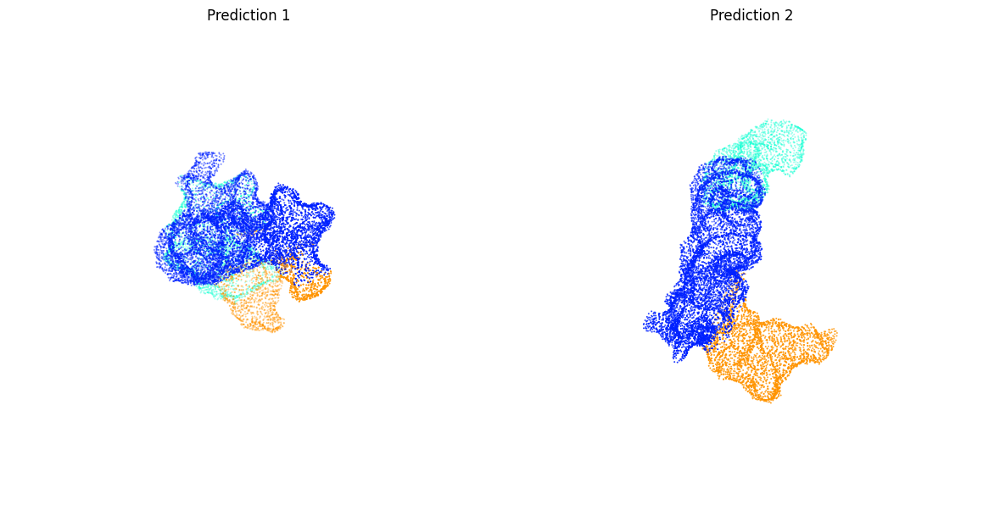

In [27]:
model_cfg = {
    'inp_feat': 'xyz',
    'num_eig': 128,
    'p_in': 3,
    'p_out': 147, #num_classes
    'n_channels': 128,
    'N_block': 4,
    'dropout': True
}

# Let's define the trainer

my_trainer = Trainer(DiffusionNet, model_cfg, train_loader, valid_loader, device=torch.device("cuda"), save_dir='./models')
#my_trainer.run()

# Let's visualize the predicted segmentation at initialization
my_trainer.visualize()

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Start val epoch
End val epoch
Epoch: 000/200, Train Loss: 4.9051, Train Acc: 1.12%, Val Loss: 4.8104, Val Acc: 1.46%


Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

...

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

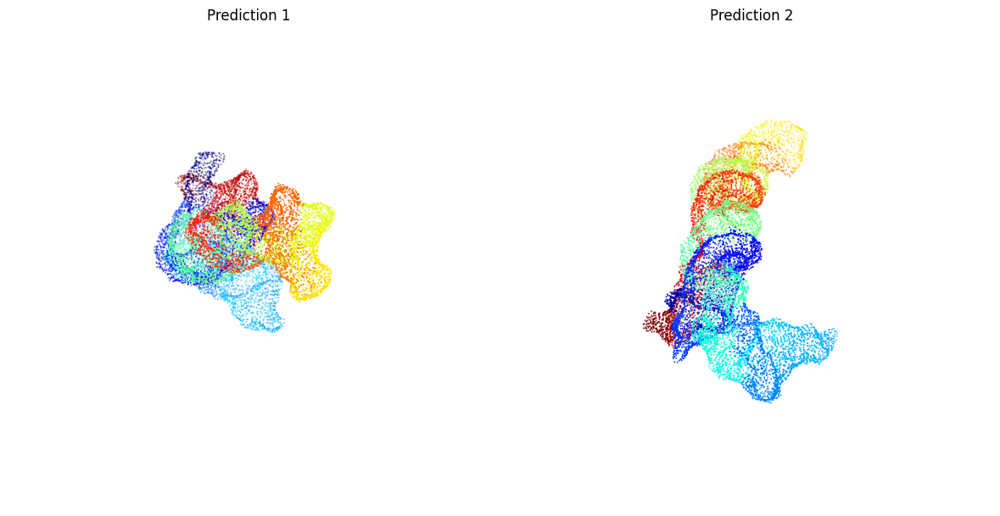

In [28]:
# We can now run the training. IT should take some time (around 2-3 hours). Do not close Colab during the training!
my_trainer.run()

# And visualize (it's supposed to be clean!)
my_trainer.visualize()

The final log shows that the model has achieved a great accuracy, both in training (79.47%) and in validation (77.22%). Furthermore, the graphical segmentation is promising.

In [29]:
!mkdir -p /content/weights/xyz_base
!cp /content/models/model_final.pth /content/weights/xyz_base/
!cp /content/models/model_latest.pth /content/weights/xyz_base/

### Question 8: Ablation studies

#### This is the final question of this lab which involves several subquestions. The objective is to understand the utility of different components of DiffusionNet block built during this session. More specifically, we will make one change at a time to the above network to understand how the segmentation accuracy varies.


1. Remove the learned diffusion module such that a "Diffusion" block consists of MLP + Gradient features.

2. Remove the Gradient feature module such that a "Diffusion" block consists of Diffusion + MLP features.

3. Instead of feeding in the `xyz` coordinate as features, what happens if either of HKS and/or WKS is used as a feature?


The first two question consists of reimplementing `DiffusionNet` module such that it incorporates aforementioned changes into the blocks. Either create a new class or add arguments which you'll use in the `model_cfg` dictionary.

For the last question, please pay attention to `inp_feat` and `p_in`.

In [30]:
### TODO:

'''This first case just consists in removing the diffusion part of the block and being careful with its consequences.
The input of the spatial gradient features will be x_in (not x_diffused) and the MiniMLP will have 2*n_channels as input (not 3*n_channels),
which are x_in and the spatial gradient features.
'''

class DiffusionNetBlock_no_diffusion(nn.Module):
    """
    Complete Diffusion block
    """

    def __init__(self, n_channels, mlp_hidden_dims, dropout=True):
        """
        Initializes the module.

        Parameters
        ------------------
        n_channels      : int - number of feature functions (serves as both input and output)
        mlp_hidden_dims : list of int - sizes of HIDDEN layers of the miniMLP.
                          You should add the input and output dimension to it.
        """
        super(DiffusionNetBlock_no_diffusion, self).__init__()

        # Specified dimensions
        self.n_channels = n_channels

        self.dropout = dropout

        # Diffusion block
        self.spatial_gradient = SpatialGradient(n_channels)
        self.MLP = MiniMLP([2*n_channels] + mlp_hidden_dims + [n_channels], dropout)


    def forward(self, x_in, vertex_areas, evals, evecs, gradX, gradY):
        """
        Parameters
        -------------------
        x_in         : (B,n,p) - Tensor of input signal.
        vertex_areas : (B,n) - Tensor of vertex areas
        evals        : (B, K,) batch of eigenvalues
        evecs        : (B, n, K) batch of eigenvectors
        gradX        : Half of gradient matrix, sparse real tensor with dimension [B,N,N]
        gradY        : Half of gradient matrix, sparse real tensor with dimension [B,N,N]

        Output
        -------------------
        x_out : (B,n,p) - Tensor of output signal.
        """

        # Manage dimensions
        B = x_in.shape[0] # batch dimension


        # Compute the batch of gradients
        x_grads = [] # Manually loop over the batch
        for b in range(B):
            # gradient after diffusion
            x_gradX = torch.mm(gradX[b,...], x_in[b,...])
            x_gradY = torch.mm(gradY[b,...], x_in[b,...])

            x_grads.append(torch.stack((x_gradX, x_gradY), dim=-1))

        x_grad = torch.stack(x_grads, dim=0)  # (B, N, P, 2)

        # TODO EVALUATE GRADIENT FEATURES

        grad_feat = self.spatial_gradient(x_grad)

        # TODO APPLY THE MLP TO THE CONCATENATED FEATURES

        out = self.MLP(torch.cat((x_in, grad_feat), dim = 2))

        # TODO APPLY THE RESIDUAL CONNECTION
        out = out + x_in

        return out

*Comments*

We can clearly see that this first ablation leads to a model that does not work well, achieving accuracies of only 6.28% and 6.29% in training and validation, respectively. These results highlight the key function of the diffusion component in the DiffusionBlock: without it, the model cannot perform the task correctly. The diffusion module operates globally, whereas the gradient module is strictly local, as it only involves computations with the immediate neighbors of each vertex.

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Start val epoch
End val epoch
Epoch: 000/200, Train Loss: 4.9029, Train Acc: 1.04%, Val Loss: 4.8350, Val Acc: 1.22%


Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

...

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

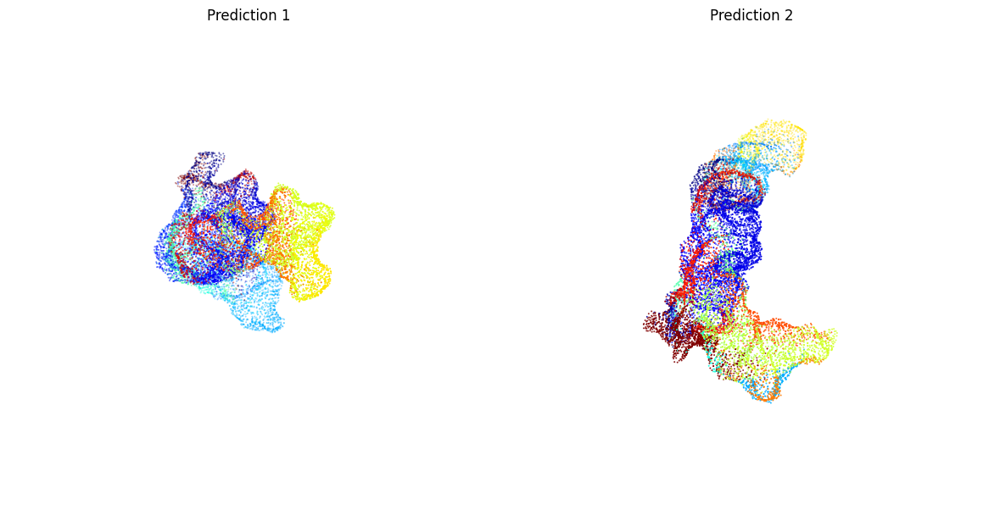

In [31]:
exp_name = 'xyz_no_diffusion'
save_dir = f'/content/weights/{exp_name}'
os.makedirs(save_dir, exist_ok=True)

model_cfg_1 = {
    'inp_feat': 'xyz',
    'num_eig': 128,
    'p_in': 3,
    'p_out': 147, #num_classes
    'n_channels': 128,
    'N_block': 4,
    'dropout': True,
    'block_cls': DiffusionNetBlock_no_diffusion
}

# Let's define the trainer

my_trainer_1 = Trainer(DiffusionNet, model_cfg_1, train_loader, valid_loader, device=torch.device("cuda"), save_dir=save_dir)

my_trainer_1.run()

my_trainer_1.visualize()

In [32]:
### TODO:

'''This second case just consists in removing the spatial gradient part of the block and being careful with its consequences.
The MiniMLP will have 2*n_channels as input (not 3*n_channels), which are x_diffused and x_in, and evidently, it is not necessary to add the spatial gradient features.
compute the gradients of the diffused points.
'''

class DiffusionNetBlock_no_gradient(nn.Module):
    """
    Complete Diffusion block
    """

    def __init__(self, n_channels, mlp_hidden_dims, dropout=True):
        """
        Initializes the module.

        Parameters
        ------------------
        n_channels      : int - number of feature functions (serves as both input and output)
        mlp_hidden_dims : list of int - sizes of HIDDEN layers of the miniMLP.
                          You should add the input and output dimension to it.
        """
        super(DiffusionNetBlock_no_gradient, self).__init__()

        self.diffusion = SpectralDiffusion(n_channels)

        # Specified dimensions
        self.n_channels = n_channels

        self.dropout = dropout

        # Diffusion block
        self.MLP = MiniMLP([2*n_channels] + mlp_hidden_dims + [n_channels], dropout)


    def forward(self, x_in, vertex_areas, evals, evecs, gradX, gradY):
        """
        Parameters
        -------------------
        x_in         : (B,n,p) - Tensor of input signal.
        vertex_areas : (B,n) - Tensor of vertex areas
        evals        : (B, K,) batch of eigenvalues
        evecs        : (B, n, K) batch of eigenvectors
        gradX        : Half of gradient matrix, sparse real tensor with dimension [B,N,N]
        gradY        : Half of gradient matrix, sparse real tensor with dimension [B,N,N]

        Output
        -------------------
        x_out : (B,n,p) - Tensor of output signal.
        """

        # Manage dimensions
        B = x_in.shape[0] # batch dimension

        # Diffusion block
        x_diffuse = self.diffusion(x_in, evals, evecs, vertex_areas) # DIFFUSED X_in  # (B, N, p)

        # TODO APPLY THE MLP TO THE CONCATENATED FEATURES

        out = self.MLP(torch.cat((x_in, x_diffuse), dim = 2))

        # TODO APPLY THE RESIDUAL CONNECTION
        out = out + x_in

        return out

*Comments*

Unlike the first ablation, removing the spatial gradient features does not drastically hurt the model. It still performs relatively well in the segmentation task (61.54% and 60.52% accuracies), despite not reaching the metrics of the complete DiffusionNet architecture. From this, we can infer that the spatial gradient acts as a complement to the block, providing directional information—specifically, how to optimally rotate and scale gradients so they interact effectively with other channel gradients at each vertex.

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Start val epoch
End val epoch
Epoch: 000/200, Train Loss: 4.9062, Train Acc: 1.03%, Val Loss: 4.8335, Val Acc: 1.22%


Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

...

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

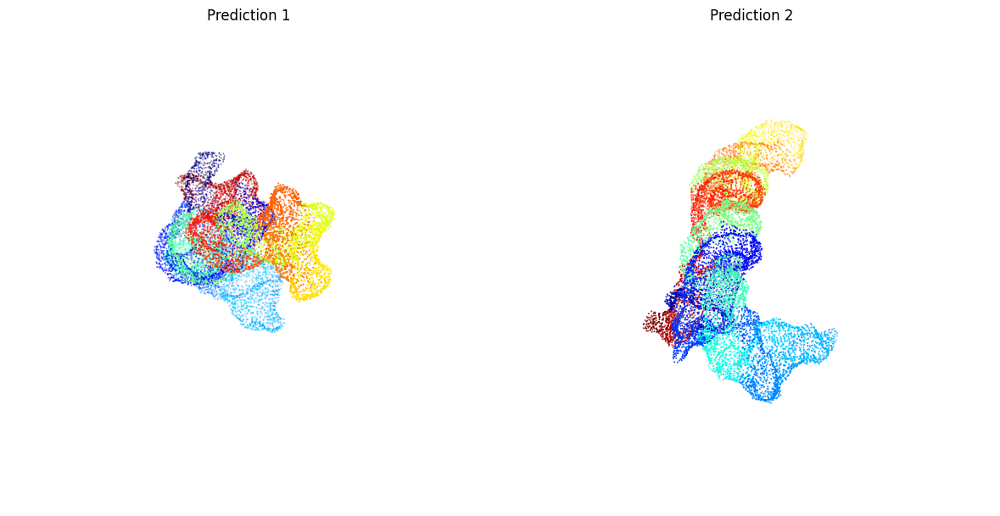

In [33]:
exp_name = 'xyz_no_gradient'
save_dir = f'/content/weights/{exp_name}'
os.makedirs(save_dir, exist_ok=True)

model_cfg_2 = {
    'inp_feat': 'xyz',
    'num_eig': 128,
    'p_in': 3,
    'p_out': 147, #num_classes
    'n_channels': 128,
    'N_block': 4,
    'dropout': True,
    'block_cls': DiffusionNetBlock_no_gradient
}

# Let's define the trainer

my_trainer_2 = Trainer(DiffusionNet, model_cfg_2, train_loader, valid_loader, device=torch.device("cuda"), save_dir=save_dir)

my_trainer_2.run()

my_trainer_2.visualize()

*Comments*     
  
Feeding the model with HKS inputs yields performance almost equivalent to using XYZ inputs (79.91% and 76.98% accuracies in training and validation respectively), showing that as long as the input features are expressive and representative, the model performs well. Furthermore, as seen in TD1, HKS is intrinsic to isometries (it is well-preserved under non-rigid deformations), whereas XYZ coordinates depend heavily on the spatial alignment of the specific mesh.

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Start val epoch
End val epoch
Epoch: 000/200, Train Loss: 4.9121, Train Acc: 1.04%, Val Loss: 4.8444, Val Acc: 1.20%


Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

...

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

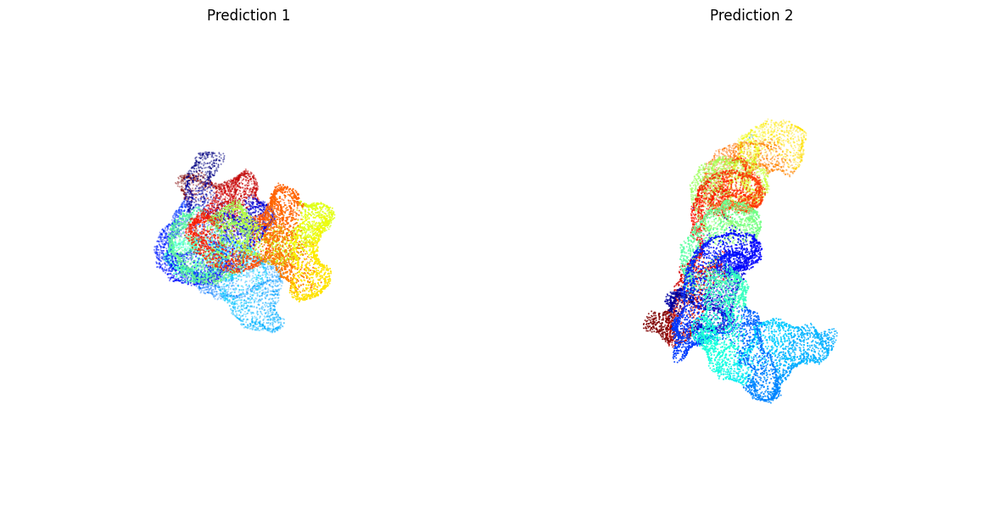

In [34]:
exp_name = 'hks'
save_dir = f'/content/weights/{exp_name}'
os.makedirs(save_dir, exist_ok=True)

model_cfg_3 = {
    'inp_feat': 'hks',
    'num_eig': 128,
    'p_in': 32,
    'p_out': 147, #num_classes
    'n_channels': 128,
    'N_block': 4,
    'dropout': True
}

# Let's define the trainer

my_trainer_3 = Trainer(DiffusionNet, model_cfg_3, train_loader, valid_loader, device=torch.device("cuda"), save_dir=save_dir)
my_trainer_3.run()

# Let's visualize the predicted segmentation at initialization
my_trainer_3.visualize()

*Comments*

Following the same argument as with HKS, feeding DiffusionNet with other representative inputs allows it to perform well, and WKS is another great descriptor for representing these shape features, obtaining 79.68% and 75.96% accuracies in training and validation respectively.

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Start val epoch
End val epoch
Epoch: 000/200, Train Loss: 4.9012, Train Acc: 1.08%, Val Loss: 4.8422, Val Acc: 1.20%


Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

...

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

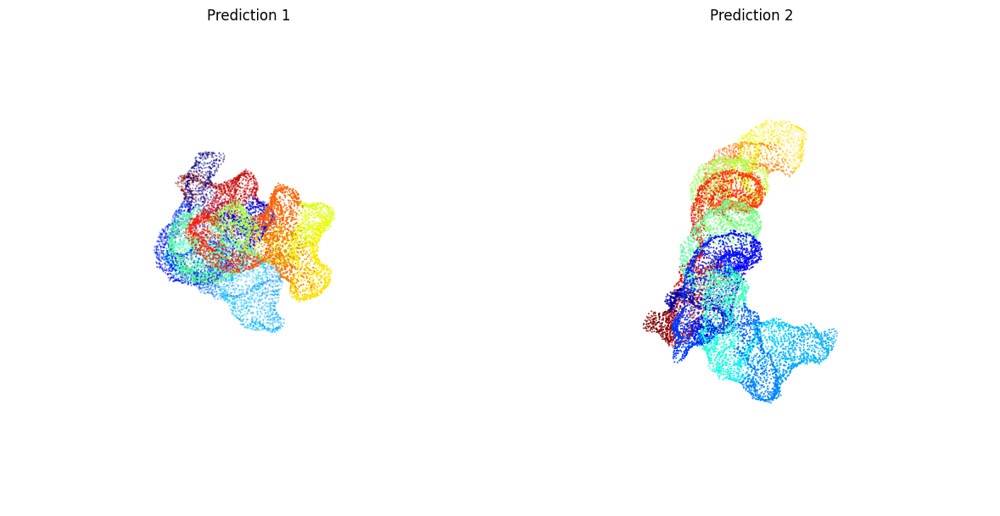

In [35]:
exp_name = 'wks'
save_dir = f'/content/weights/{exp_name}'
os.makedirs(save_dir, exist_ok=True)

model_cfg_4 = {
    'inp_feat': 'wks',
    'num_eig': 128,
    'p_in': 32,
    'p_out': 147, #num_classes
    'n_channels': 128,
    'N_block': 4,
    'dropout': True
}

# Let's define the trainer

my_trainer_4 = Trainer(DiffusionNet, model_cfg_4, train_loader, valid_loader, device=torch.device("cuda"), save_dir=save_dir)
my_trainer_4.run()

# Let's visualize the predicted segmentation at initialization
my_trainer_4.visualize()

*Comments*

Combining HKS and WKS yields the best results in our experiments (81.07% and 77.92% accuracies in training and validation respectively). This is likely due to having a richer and more expressive input signal, combined with the key advantage that both HKS and WKS are fully intrinsic to isometries.

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Start val epoch
End val epoch
Epoch: 000/200, Train Loss: 4.9068, Train Acc: 1.06%, Val Loss: 4.8396, Val Acc: 1.24%


Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

...

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

Train epoch:   0%|          | 0/60 [00:00<?, ?it/s]

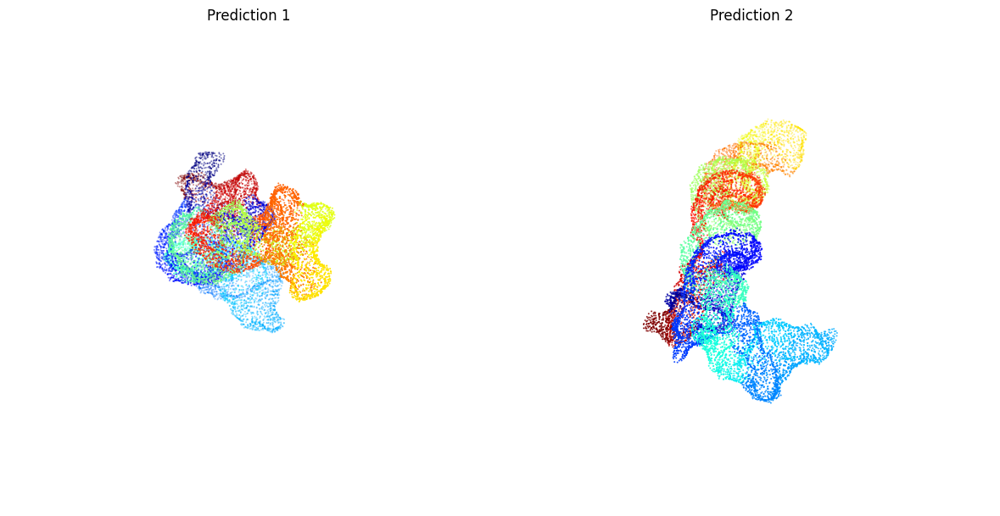

In [36]:
exp_name = 'hks+wks'
save_dir = f'/content/weights/{exp_name}'
os.makedirs(save_dir, exist_ok=True)

model_cfg_5 = {
    'inp_feat': 'hks+wks',
    'num_eig': 128,
    'p_in': 64,
    'p_out': 147, #num_classes
    'n_channels': 128,
    'N_block': 4,
    'dropout': True
}

# Let's define the trainer

my_trainer_5 = Trainer(DiffusionNet, model_cfg_5, train_loader, valid_loader, device=torch.device("cuda"), save_dir=save_dir)
my_trainer_5.run()

# Let's visualize the predicted segmentation at initialization
my_trainer_5.visualize()

In [ ]:
!cd /content && zip -r weights.zip weights